# Training utilities: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/4. Training Utilities/2_Human_Gender_CNN.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| `ModelCheckpoint(monitor='val_loss', save_best_only=True, filepath='{epoch}-{loss}-...hdf5')` | mỗi khi `val_loss` tốt nhất mới: `torch.save(model.state_dict(), 'epoch-loss-acc-val_loss-val_acc.pt')` |
| `EarlyStopping(monitor='val_loss', patience=5)` | đếm số epoch `val_loss` không giảm; ≥ 5 thì `break` |
| `ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, min_lr=0.0001)` | `torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.1, patience=5, min_lr=1e-4)` + `scheduler.step(val_loss)` |
| `TensorBoard(log_dir='./logs')` | `torch.utils.tensorboard.SummaryWriter` nếu đã cài `tensorboard`; luôn ghi thêm `log.csv` và vẽ bằng matplotlib |
| `model.load_weights('...hdf5')` | `model.load_state_dict(torch.load('...pt'))` |
| `Adam(lr=0.001)`, `epochs=100000` | `torch.optim.Adam(lr=1e-3)`, vòng lặp tối đa 100000 epoch (dừng nhờ EarlyStopping) |

> **Dữ liệu:** như notebook Gender ở mục 2 – chưa có `.npy` thì chạy bằng dữ liệu giả (có cảnh báo) để kiểm tra
> các cơ chế checkpoint / early stopping / giảm learning rate.

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

import csv

np.random.seed(2024); torch.manual_seed(2024)
num_classes = 2

ROOT = D:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def keras_init(model):
    """Khởi tạo giống mặc định Keras: kernel glorot_uniform, bias = 0
    (PyTorch mặc định dùng kaiming_uniform nên kết quả có thể lệch nhẹ nếu không làm bước này)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    return model

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

# (1) Data
### Download data at https://drive.google.com/drive/folders/0BxINLo5jshCRYW8xODhNSlkyLTQ?resourcekey=0-RNJvvSSE67Q1bMqQi3A1RQ&usp=sharing

In [3]:
# Dữ liệu WIKI 64x64 (file .npy) – tải theo link trong README, đặt vào data/gender/
GENDER = DATA / "gender"
files = ["64_64_11938_4098_train_x_onehot.npy", "64_64_11938_4098_train_y_onehot.npy",
         "64_64_5968_4098_val_x_onehot.npy", "64_64_5968_4098_val_y_onehot.npy"]
USE_DUMMY = not all((GENDER / f).exists() for f in files)

if not USE_DUMMY:
    x_train, y_train, x_test, y_test = (np.load(GENDER / f) for f in files)
else:
    print("!!! KHÔNG TÌM THẤY DỮ LIỆU data/gender/*.npy -> dùng DỮ LIỆU GIẢ (ngẫu nhiên) để KIỂM TRA CODE.")
    print("!!! Kết quả bên dưới KHÔNG có ý nghĩa; tải dữ liệu thật theo README rồi chạy lại.")
    rng = np.random.default_rng(0)
    x_train = rng.random((256, 64, 64, 1), dtype=np.float32); y_train = np.eye(2)[rng.integers(0, 2, 256)]
    x_test = rng.random((128, 64, 64, 1), dtype=np.float32);  y_test = np.eye(2)[rng.integers(0, 2, 128)]

if x_train.ndim == 3:                     # phòng trường hợp file không có trục kênh
    x_train, x_test = x_train[..., None], x_test[..., None]
x_train = np.rot90(x_train, k=3, axes=(1, 2))   # giống bản gốc: xoay ảnh về đúng chiều
x_test = np.rot90(x_test, k=3, axes=(1, 2))

# Keras: (N, 64, 64, 1) one-hot  ->  PyTorch: (N, 1, 64, 64) + nhãn số nguyên
to_t = lambda x: torch.from_numpy(np.ascontiguousarray(x.transpose(0, 3, 1, 2)).astype(np.float32))
x_train_t, x_test_t = to_t(x_train), to_t(x_test)
y_train_t, y_test_t = torch.from_numpy(y_train.argmax(1)).long(), torch.from_numpy(y_test.argmax(1)).long()
print("x_train", tuple(x_train_t.shape), "| x_test", tuple(x_test_t.shape))
train_loader = DataLoader(TensorDataset(x_train_t, y_train_t), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test_t, y_test_t), batch_size=256)

!!! KHÔNG TÌM THẤY DỮ LIỆU data/gender/*.npy -> dùng DỮ LIỆU GIẢ (ngẫu nhiên) để KIỂM TRA CODE.
!!! Kết quả bên dưới KHÔNG có ý nghĩa; tải dữ liệu thật theo README rồi chạy lại.
x_train (256, 1, 64, 64) | x_test (128, 1, 64, 64)


# (2) Declare model

In [4]:
def conv_relu(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU()]


class GenderCNN(nn.Module):
    """5 khối conv (16-32-64-128-256), mỗi khối kết thúc bằng MaxPool + Dropout(0.2); rồi FC 1024-1024-2."""
    def __init__(self, num_classes=2):
        super().__init__()
        cfg = [(1, 16, 2), (16, 32, 3), (32, 64, 3), (64, 128, 3), (128, 256, 3)]   # (vào, ra, số conv)
        layers = []
        for cin, cout, n in cfg:
            for k in range(n):
                layers += conv_relu(cin if k == 0 else cout, cout)
            layers += [nn.MaxPool2d(2), nn.Dropout(0.2)]
        self.features = nn.Sequential(*layers)                     # 64x64 -> 2x2x256
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, num_classes))                          # logits (softmax nằm trong CrossEntropyLoss)

    def forward(self, x):
        return self.classifier(self.features(x))


model = keras_init(GenderCNN(num_classes)).to(DEVICE)
summary(model, (1, 64, 64), keras_params=4_063_570)

Layer                 Type            Output shape                   Param #
features.0            Conv2d          (1, 16, 64, 64)                    160
features.1            ReLU            (1, 16, 64, 64)                      0
features.2            Conv2d          (1, 16, 64, 64)                  2,320
features.3            ReLU            (1, 16, 64, 64)                      0
features.4            MaxPool2d       (1, 16, 32, 32)                      0
features.5            Dropout         (1, 16, 32, 32)                      0
features.6            Conv2d          (1, 32, 32, 32)                  4,640
features.7            ReLU            (1, 32, 32, 32)                      0
features.8            Conv2d          (1, 32, 32, 32)                  9,248
features.9            ReLU            (1, 32, 32, 32)                      0
features.10           Conv2d          (1, 32, 32, 32)                  9,248
features.11           ReLU            (1, 32, 32, 32)                      0

# (3) Train defined model – kèm các training utilities

In [5]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 100000          # dùng EarlyStopping nên đặt số epoch thật lớn (giống bản gốc)
if USE_DUMMY:
    epochs = 40          # dữ liệu giả: giới hạn để không chạy mãi, đủ dài để early stopping kích hoạt

# ModelCheckpoint: lưu mô hình tốt nhất theo val_loss
CKPT_DIR = ROOT / "outputs" / "gender_utilities"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
# EarlyStopping: dừng nếu val_loss không giảm sau 5 epoch
early_stopping_after_epochs = 5
# ReduceLROnPlateau: new_lr = lr x 0.1 nếu val_loss không giảm sau 5 epoch, không nhỏ hơn 1e-4
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=5, min_lr=0.0001)
# TensorBoard: dùng nếu có cài tensorboard; luôn ghi log.csv
try:
    from torch.utils.tensorboard import SummaryWriter
    writer = SummaryWriter(log_dir=str(ROOT / "outputs" / "logs"))
except Exception:
    writer = None
    print("(chưa cài tensorboard -> chỉ ghi log.csv và vẽ bằng matplotlib)")

best_val, wait, best_ckpt, logs = float("inf"), 0, None, []
starting_time = time.time()
for epoch in range(1, epochs + 1):
    t0 = time.time()
    loss, acc = run_epoch(model, train_loader, loss_fn, accuracy, optimizer)
    val_loss, val_acc = run_epoch(model, test_loader, loss_fn, accuracy)
    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch}/{epochs} - {time.time() - t0:.0f}s - loss: {loss:.4f} - acc: {acc:.4f} "
          f"- val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f} - lr: {lr_now:g}", flush=True)
    logs.append(dict(epoch=epoch, loss=loss, acc=acc, val_loss=val_loss, val_acc=val_acc, lr=lr_now))
    if writer:
        for k in ("loss", "acc", "val_loss", "val_acc"):
            writer.add_scalar(k, logs[-1][k], epoch)

    if val_loss < best_val:                                   # ModelCheckpoint(save_best_only=True)
        best_val, wait = val_loss, 0
        best_ckpt = CKPT_DIR / f"{epoch:06d}-{loss:.4f}-{acc:.4f}-{val_loss:.4f}-{val_acc:.4f}.pt"
        torch.save(model.state_dict(), best_ckpt)
        print(f"   -> val_loss cải thiện, lưu checkpoint {best_ckpt.name}")
    else:                                                     # EarlyStopping(patience=5)
        wait += 1
        if wait >= early_stopping_after_epochs:
            print(f"   -> EarlyStopping: val_loss không giảm sau {early_stopping_after_epochs} epoch, dừng ở epoch {epoch}")
            break
    scheduler.step(val_loss)                                  # ReduceLROnPlateau

if writer:
    writer.close()
with open(CKPT_DIR / "log.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=logs[0].keys()); w.writeheader(); w.writerows(logs)
print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))

(chưa cài tensorboard -> chỉ ghi log.csv và vẽ bằng matplotlib)


Epoch 1/40 - 2s - loss: 0.6910 - acc: 0.5312 - val_loss: 0.7930 - val_acc: 0.5156 - lr: 0.001


   -> val_loss cải thiện, lưu checkpoint 000001-0.6910-0.5312-0.7930-0.5156.pt


Epoch 2/40 - 2s - loss: 0.7861 - acc: 0.4883 - val_loss: 0.6943 - val_acc: 0.4844 - lr: 0.001


   -> val_loss cải thiện, lưu checkpoint 000002-0.7861-0.4883-0.6943-0.4844.pt


Epoch 3/40 - 2s - loss: 0.6957 - acc: 0.4648 - val_loss: 0.6941 - val_acc: 0.4844 - lr: 0.001


... (13 outputs left out)

Epoch 11/40 - 2s - loss: 0.6907 - acc: 0.5352 - val_loss: 0.6930 - val_acc: 0.5156 - lr: 0.001


Epoch 12/40 - 2s - loss: 0.6905 - acc: 0.5352 - val_loss: 0.6932 - val_acc: 0.5156 - lr: 0.001


Epoch 13/40 - 1s - loss: 0.6905 - acc: 0.5352 - val_loss: 0.6934 - val_acc: 0.5156 - lr: 0.001


   -> EarlyStopping: val_loss không giảm sau 5 epoch, dừng ở epoch 13
> training time is 0.3519 minutes


### Đường cong train/validation (thay cho TensorBoard) và danh sách checkpoint

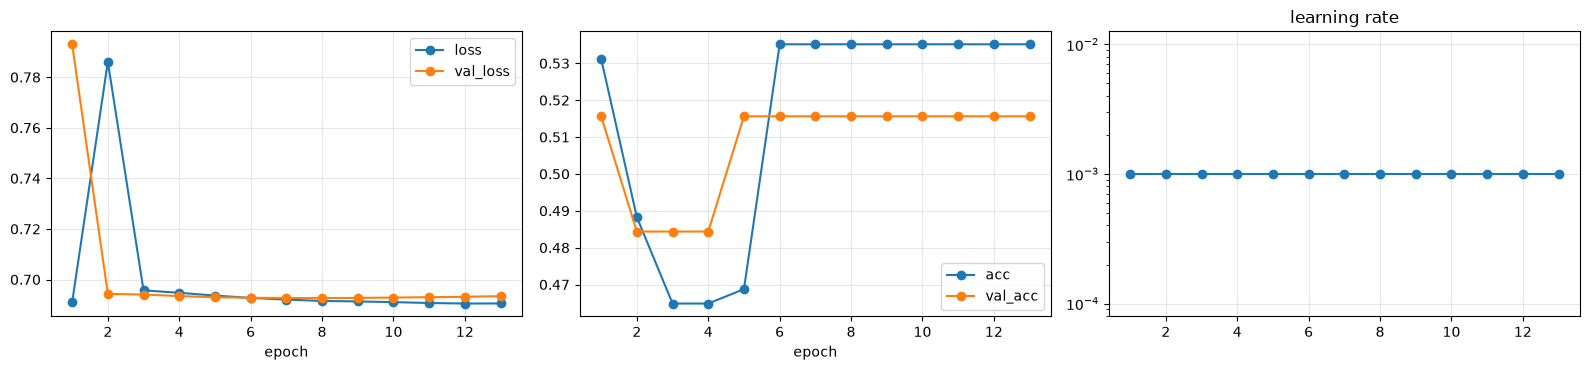

Checkpoint files:
   000001-0.6910-0.5312-0.7930-0.5156.pt
   000002-0.7861-0.4883-0.6943-0.4844.pt
   000003-0.6957-0.4648-0.6941-0.4844.pt
   000004-0.6948-0.4648-0.6934-0.4844.pt
   000005-0.6936-0.4688-0.6930-0.5156.pt
   000006-0.6927-0.5352-0.6928-0.5156.pt
   000007-0.6921-0.5352-0.6927-0.5156.pt
   000008-0.6915-0.5352-0.6927-0.5156.pt


[None, None, None, None, None, None, None, None]

In [6]:
ep = [r["epoch"] for r in logs]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (a, b) in zip(axes[:2], [("loss", "val_loss"), ("acc", "val_acc")]):
    ax.plot(ep, [r[a] for r in logs], marker="o", label=a); ax.plot(ep, [r[b] for r in logs], marker="o", label=b)
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
axes[2].plot(ep, [r["lr"] for r in logs], marker="o"); axes[2].set_yscale("log"); axes[2].set_title("learning rate"); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Checkpoint files:"); [print("  ", p.name) for p in sorted(CKPT_DIR.glob("*.pt"))]

### Load trained model and evaluate it again with validation set

In [7]:
model.load_state_dict(torch.load(best_ckpt, map_location=DEVICE))    # model.load_weights('...hdf5')
print("loaded", best_ckpt.name)
test_loss, test_acc = run_epoch(model, test_loader, loss_fn, accuracy)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc, "(DỮ LIỆU GIẢ – chỉ kiểm tra code)" if USE_DUMMY else "")

loaded 000008-0.6915-0.5352-0.6927-0.5156.pt


Test loss: 0.6926602125167847
Test accuracy: 0.515625 (DỮ LIỆU GIẢ – chỉ kiểm tra code)


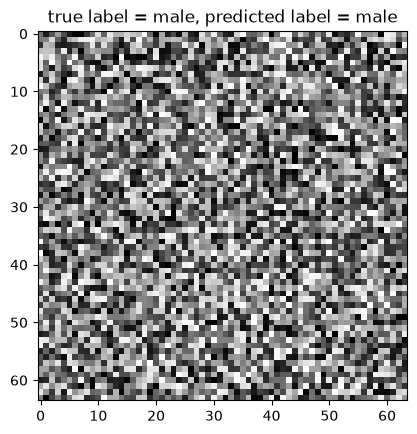

In [8]:
def int2gender(num):
    return "female" if num == 0 else "male"


model.eval()
i = np.random.choice(len(x_test_t), size=1)[0]
with torch.no_grad():
    pred_label = model(x_test_t[i:i + 1].to(DEVICE)).argmax(1).item()
plt.imshow(x_test_t[i, 0], cmap="gray")
plt.title("true label = %s, predicted label = %s" % (int2gender(y_test_t[i].item()), int2gender(pred_label)))
plt.show()